In [1]:
import sys, types

# matplotlib-3.5.1-nspkg.pth pre-registers the system mpl_toolkits intoZa
# sys.modules at Python startup — before any code runs.
# Clear it and redirect to the local compatible version.
for key in list(sys.modules):
    if key.startswith('mpl_toolkits'):
        del sys.modules[key]

_local = '/home/noah/.local/lib/python3.10/site-packages/mpl_toolkits'
m = types.ModuleType('mpl_toolkits')
m.__path__ = [_local]
sys.modules['mpl_toolkits'] = m

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.ticker as ticker  
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import HTML
from numba import prange
from scipy.interpolate import griddata


print(f"matplotlib: {plt.matplotlib.__version__}  |  Axes3D: OK")

matplotlib: 3.10.9  |  Axes3D: OK


In [27]:
def plot_scatter_regular(x_vals, y_vals, x_spacing, title, ymax=None, yerr=None, errbar_step=1):
    fig, ax = plt.subplots(figsize=(6, 6))
    if yerr is not None:
        triples = sorted(zip(x_vals, y_vals, yerr))
        x_sorted, y_sorted, yerr_sorted = zip(*triples)
        ax.errorbar(x_sorted, y_sorted, yerr=yerr_sorted, color='blue',
                    ecolor='steelblue', elinewidth=0.8, capsize=3, capthick=0.8,
                    errorevery=errbar_step)
    else:
        pairs = sorted(zip(x_vals, y_vals))
        x_sorted, y_sorted = zip(*pairs)
        ax.plot(x_sorted, y_sorted, color='blue')
    ax.set_xlim(np.min(x_vals), np.max(x_vals))
    ax.set_ylim(0, ymax)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(x_spacing))
    ax.grid(True)
    ax.grid(True, which='major', linestyle='--', alpha=0.5)
    ax.grid(True, which='minor', linestyle=':', alpha=0.3)
    ax.minorticks_on()
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def find_vel_avg_3D(points, activations):
    actv = activations.copy()
    points = np.array(polar_to_cartesian_3D(points))
    total_weight = np.sum(activations)
    x_bar = np.sum(points[:, X] * activations) / total_weight
    y_bar = np.sum(points[:, Y] * activations) / total_weight
    z_bar = np.sum(points[:, Z] * activations) / total_weight
    return np.array((x_bar, y_bar, z_bar))

def rand_link_func(y, sigma, inv_sqrt_n):
    out = np.empty_like(y)
    for i in prange(y.size):
        out[i] = np.random.normal(0.0, sigma) * inv_sqrt_n
    return out

def wrap_around(a1, a2):
    return (((a1-a2) + np.pi) % (2*np.pi)) - np.pi

def max_abs_eigenvalue(M):
    eigenvalues = np.linalg.eigvals(M)
    return np.max(np.abs(eigenvalues))

def cartesian_to_polar_3D(points):
    cpy = points.copy()
    for i in range(len(cpy)):
        x, y, z = cpy[i]
        r = np.sqrt(x**2 + y**2 + z**2)
        theta = np.arctan2(y, x)
        if r != 0.0:
            phi = np.arccos(z / r)
        else:
            phi = 0.0
        cpy[i] = r, theta, phi
    return cpy

def polar_to_cartesian_3D(points):
    cpy = points.copy()
    for i in range(len(cpy)):
        r, theta, phi = cpy[i]
        x = r * np.sin(phi) * np.cos(theta)
        y = r * np.sin(phi) * np.sin(theta)
        z = r * np.cos(phi)
        cpy[i] = x, y, z
    return cpy

def geodesic_distance(point1, point2):
    alpha = np.arccos(np.clip(np.cos(point1[THETA]) * np.cos(point2[THETA]) + np.sin(point1[THETA]) * np.sin(point2[THETA]) * np.cos(point1[PHI] - point2[PHI]), -1, 1))
    return alpha

def plot_polar_points_3D(points, scalar_vals, title, plot_vector):
    fig = plt.figure(figsize=(3, 3))
    ax = fig.add_subplot(111, projection='3d')
    pts = np.array(polar_to_cartesian_3D(points.copy()))
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=scalar_vals, cmap='Blues', vmin=-0.05, vmax=max(scalar_vals), s=10)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-1, 1)
    ax.set_box_aspect([1, 1, 1])
    ax.set_title(title)
    vec = find_vel_avg_3D(points, scalar_vals)
    normalized = vec / np.linalg.norm(vec)
    if plot_vector: ax.quiver(0, 0, 0, normalized[X], normalized[Y], normalized[Z], color='red')
    plt.show()

def plot_3d_heatmap(angle_grid, z_vals, title):
    phi_vals   = angle_grid[:, PHI]
    theta_vals = angle_grid[:, THETA]
    z_clamped  = np.maximum(z_vals, 0)
    phi_grid   = np.linspace(phi_vals.min(),   phi_vals.max(),   50)
    theta_grid = np.linspace(theta_vals.min(), theta_vals.max(), 50)
    PHI_G, THETA_G = np.meshgrid(phi_grid, theta_grid)
    Z_G = griddata((phi_vals, theta_vals), z_clamped, (PHI_G, THETA_G), method='linear')
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(PHI_G, THETA_G, Z_G, cmap='plasma', vmax=np.nanmax(Z_G) + 0.15)
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
    ax.set_yticks([0, np.pi/2, np.pi])
    ax.set_yticklabels(['0', 'π/2', 'π'])
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(0, np.pi)
    ax.set_zlim(0, 2)
    ax.set_xlabel('phi')
    ax.set_ylabel('theta')
    ax.set_title(title)
    plt.show()

def plot_kernel_3panel(sphere_nodes, M):
    phi   = sphere_nodes[:, PHI]
    theta = sphere_nodes[:, THETA]
    N = len(sphere_nodes)

    phi_i   = np.repeat(phi,   N)
    theta_i = np.repeat(theta, N)
    phi_j   = np.tile(phi,   N)
    theta_j = np.tile(theta, N)
    m_flat  = M.flatten()

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    combos = [
        (phi_i,   phi_j,   'φ_i', 'φ_j'),
        (theta_i, theta_j, 'θ_i', 'θ_j'),
        (phi_i,   theta_j, 'φ',   'θ'),
    ]
    for ax, (x, y, xlabel, ylabel) in zip(axes, combos):
        sc = ax.scatter(x, y, c=m_flat, cmap='bwr', s=10,
                        vmin=m_flat.min(), vmax=m_flat.max())
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    plt.subplots_adjust(right=0.88, wspace=0.35)
    cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
    fig.colorbar(sc, cax=cbar_ax, label='M[i,j]')
    plt.suptitle('All Node Pairs of Kernel matrix M')
    plt.show()

def find_closest_node(points, phi, theta):
    test_pt = np.array((1.0, phi, theta))
    distances = [geodesic_distance(test_pt, nodes[i]) for i in range(len(nodes))]
    return np.argmin(distances), np.min(distances)

def plot_kernel_one_node(ref_phi, ref_theta, sphere_nodes, M, nu):
    # Convention (see cartesian_to_polar_3D): idx1 = azimuth arctan2(y,x) in [-pi,pi],
    # idx2 = colatitude arccos(z/r) in [0,pi].
    ref_idx, _ = find_closest_node(sphere_nodes, ref_phi, ref_theta)

    # Rotate the whole sphere so the reference node lands at the map center.
    # After rotation the node sits at (phi=0, theta=pi/2), surrounded by nodes
    # in every direction; x spans [-pi, pi], y spans [0, pi].
    cart  = np.array(polar_to_cartesian_3D(sphere_nodes.copy()))
    c_ref = cart[ref_idx] / np.linalg.norm(cart[ref_idx])

    target = np.array([1.0, 0.0, 0.0])             # map center direction
    v = np.cross(c_ref, target)
    s = np.linalg.norm(v)
    c = np.dot(c_ref, target)
    if s < 1e-8:                                    # already aligned / antipodal
        R = np.eye(3) if c > 0 else np.diag([-1.0, -1.0, 1.0])
    else:
        vx = np.array([[0, -v[2], v[1]],
                       [v[2], 0, -v[0]],
                       [-v[1], v[0], 0]])
        R = np.eye(3) + vx + vx @ vx * ((1 - c) / s**2)

    rot = cart @ R.T
    phi_c   = np.arctan2(rot[:, 1], rot[:, 0])          # x in [-pi, pi], ref -> 0
    theta_c = np.arccos(np.clip(rot[:, 2], -1, 1))      # y in [0, pi],  ref -> pi/2

    color = M[ref_idx, :]                             # this node's kernel row
    vmax  = np.max(np.abs(color)) or 1.0              # bwr, white centered at 0

    fig, ax = plt.subplots(figsize=(8, 4))
    phi_w   = np.concatenate([phi_c - 2*np.pi, phi_c, phi_c + 2*np.pi])
    theta_w = np.tile(theta_c, 3)
    color_w = np.tile(color, 3)

    sc = ax.tripcolor(phi_w, theta_w, color_w, cmap='bwr', vmin=-vmax, vmax=vmax, shading='gouraud')
    
    ax.plot(0, np.pi/2, marker='*', color='k', markersize=16, zorder=5)   # reference node

    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(np.pi, 0)                              # theta = 0 at top, pi at bottom
    ax.set_aspect('equal')
    ax.set_xlabel('phi (azimuth) [rad]')
    ax.set_ylabel('theta (colatitude) [rad]')
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
    ax.set_yticks([0, np.pi/2, np.pi])
    ax.set_yticklabels(['0', 'π/2', 'π'])

    fig.colorbar(sc, label='M[ref, j]')
    plt.title(f'Kernel M around reference node, nu={nu}')
    plt.tight_layout()
    plt.show()


In [28]:
#RAN Functions, all assume polar coordinates

def genetate_connection_matrix(sphere_points, v_val):
    num_nodes = len(sphere_points)
    M = np.zeros((num_nodes, num_nodes))
    alphas = np.zeros((num_nodes, num_nodes))

    for i in range(num_nodes):
        for j in range(num_nodes):           
            alphas[i, j] = geodesic_distance(sphere_points[i], sphere_points[j])
            M[i, j] = np.cos(np.pi * np.power((alphas[i,j]/np.pi), v_val)) * (1/num_nodes)


    return alphas, M

def generate_sensory_input(sphere_points, targets, kappa):
    num_nodes = len(sphere_points)
    b = np.zeros(num_nodes)

    for j in range(len(targets)):
        for i in range(num_nodes):
            target_point = np.array((targets[j][MAG], targets[j][PHI], targets[j][THETA])) 
            alpha = geodesic_distance(sphere_points[i], target_point)
            b[i] += np.exp(kappa * (np.cos(alpha) - 1.0)) * targets[j][QUALITY]

    b *= (1/np.sqrt(num_nodes)) 
    return b

def generate_equal_sensory_input(sphere_points, targets, kappa):
    b = generate_sensory_input(sphere_points, targets, kappa)

    for j in range(len(targets)):
        index, alpha = find_closest_node(sphere_points, targets[j][PHI], targets[j][THETA])
        b[index] = np.max(b)
    
    return b

def generate_RAN_with_history(u_val, num_nodes, M, num_integrations, dt, sigma, beta, b):
    # Static RAN run
    z      = np.zeros(num_nodes) 
    z_next = np.zeros(num_nodes)
    y      = np.zeros((num_integrations, num_nodes))
    
    for t in range(num_integrations):
        noise = rand_link_func(y[t], sigma * np.sqrt(dt), 1.0/np.sqrt(num_nodes))
        z = z + dt * (-z + np.tanh(u_val * (M @ z) + b - beta) - np.tanh(-beta)) + noise 
        y[t] = z

    return y

    


# Mean-Field-Model RAN Extended to 3D

The goal is to extend a 2D mean field model ring attractor network (RAN) into a simple 3D version to be used on a crazyflie drone.

# Storing 3D RAN Nodes: Possible Methods

## Fibonacci Sphere

To represent a ring attractor in spherical coordinates, the Fibonacci Sphere will be used. This sphere generates nearly equidistant points on the surface of a sphere using the Golden Ratio and Fibonacci spirals. 

For $N$ points indexed $i = 0, 1, \ldots, N-1$:

$$z_i = 1 - \frac{2i}{N-1}$$

$$r_i = \sqrt{1 - z_i^2}$$

$$\theta_i = i \cdot \frac{2\pi}{\varphi^2}, \quad \text{where } \varphi = \frac{1 + \sqrt{5}}{2}$$

Then convert to Cartesian coordinates:

$$x_i = r_i \cos\theta_i, \qquad y_i = r_i \sin\theta_i, \qquad z_i = z_i$$

**Problem**: nodes are generated asymmetricly, which will create an uneven kernel matrix M. Nodes will not be equally spaced, and may cause heading tracking issues.


## Icosphere with Set Resolution

An icosphere is the only 3D sphere that can mathematically have equally-spaced points. It is recursively constructed using triangles. 

Start with 12 vertices and 20 faces on the base icosahedron. Each subdivision splits every triangle into 4, adding new vertices on each edge. The formula is:

$$N = 10 · 4^n + 2$$

E.g. 12, 42, 162, 642, etc

Now, when calculating the kernel matrix, all angular distances will be symmetrical like the 2D version.

In [29]:
import pyvista as pv

# Create an icosphere with radius 2 and 2 levels of subdivision
icosphere_test = pv.Icosphere(radius=2.0, nsub=1)

# Visualize it immediately
# icosphere_test .plot(show_edges=True, window_size=[300, 300])
# fig = plt.figure(figsize=(3, 3))
# ax = fig.add_subplot(111, projection='3d')

# pts = icosphere_test.points
# ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=10)
# ax.set_xlabel('x')
# ax.set_ylabel('y')
# ax.set_zlabel('z')
# plt.show()


In [30]:
#Constants for indexing
X = MAG = 0
Y = PHI = 1     #phi = xy angle
Z = THETA = 2   #theta = z axis angle
QUALITY = 3

#Icosphere generation
nsub = 3
icosphere = pv.Icosphere(radius=1.0, nsub=nsub)

#Polar form of nodes [r, theta, phi], sphere points are not sorted/ordered
nodes = cartesian_to_polar_3D(icosphere.points.copy())

# print(nodes)

# Parameters
N_s   = 10 * 4**nsub +2
beta = 1.5
v = 0.5
dt = 0.1
sigma = 1.5
kappa = 5.0    
u = 32.0

target1 = [2.0, 0, np.pi/2, 20.0]   #distance, phi, theta, quality
target2 = [2.0, (-np.pi), np.pi/2, 20.0]   #distance, phi, theta, quality
targets = [target1, target2]


In [31]:
#Fibonacci sphere generation (formula per the "Storing 3D RAN Nodes" markdown above)
# No dedicated PyPI package implements this -- it's short enough that none
# exists (checked: no fibonacci-sphere/spherical-sampling/etc. package on
# PyPI) -- so this uses numpy directly, same as every other array op here.

N_fib = len(nodes)   # match the icosphere's node count for a fair side-by-side comparison

i_fib = np.arange(N_fib)
z_fib = 1 - 2 * i_fib / (N_fib - 1)
r_xy_fib = np.sqrt(1 - z_fib**2)
golden_ratio = (1 + np.sqrt(5)) / 2
golden_angle = 2 * np.pi / golden_ratio**2
theta_fib = i_fib * golden_angle

fib_points = np.stack([
    r_xy_fib * np.cos(theta_fib),
    r_xy_fib * np.sin(theta_fib),
    z_fib,
], axis=1)

#Polar form of nodes [r, theta, phi], same convention as `nodes` above
fib_nodes = cartesian_to_polar_3D(fib_points.copy())


In [32]:
#Lloyd relaxation on the icosphere -- fixes the 12 fixed valence-5 vertices
#that make the plain icosphere ~16% denser there than elsewhere (see the
#"Storing 3D RAN Nodes" markdown above, and the -18deg rotation workaround in
#crazyflies.yaml that this should eventually make unnecessary).
#
#Repeatedly computes the spherical Voronoi diagram of the current points and
#moves each point to its own cell's area-weighted centroid (Centroidal
#Voronoi Tessellation / Lloyd's algorithm, generalized to the sphere).
from scipy.spatial import SphericalVoronoi

def spherical_triangle_area(a, b, c):
    # Solid angle subtended by triangle a,b,c as seen from the sphere's
    # center == the triangle's area on the unit sphere (Van Oosterom &
    # Strackee formula) -- much simpler than L'Huilier's theorem.
    numer = np.abs(np.dot(a, np.cross(b, c)))
    denom = 1.0 + np.dot(a, b) + np.dot(b, c) + np.dot(c, a)
    return 2.0 * np.arctan2(numer, denom)

def lloyd_relax_sphere(points, n_iter=30):
    points = points / np.linalg.norm(points, axis=1, keepdims=True)
    for _ in range(n_iter):
        sv = SphericalVoronoi(points, radius=1.0, center=np.zeros(3))
        sv.sort_vertices_of_regions()
        new_points = np.empty_like(points)
        for i, region in enumerate(sv.regions):
            verts = sv.vertices[region]
            gen = points[i]
            # Fan-triangulate the (convex) spherical polygon from its own
            # generator point, area-weight each fan triangle's centroid.
            centroid = np.zeros(3)
            for j in range(len(verts)):
                a, b = verts[j], verts[(j + 1) % len(verts)]
                area = spherical_triangle_area(gen, a, b)
                tri_mid = gen + a + b
                centroid += area * (tri_mid / np.linalg.norm(tri_mid))
            new_points[i] = centroid / np.linalg.norm(centroid)
        points = new_points
    return points

lloyd_points = lloyd_relax_sphere(icosphere.points.copy())

#Polar form of nodes [r, theta, phi], same convention as `nodes` above
lloyd_nodes = cartesian_to_polar_3D(lloyd_points.copy())


## Symmetry-matched target placement (debiasing 3-target competition)

Even on the Lloyd-relaxed mesh above, an *arbitrarily* placed set of 3 equal-quality
targets is not actually fair: each target's local node neighborhood sums to a
slightly different total, and once the network's gain is pushed past its
bifurcation threshold (winner-take-all), that tiny, permanent gap deterministically
decides the winner every single trial -- not the targets' quality, just where they
happened to land on the mesh.

The Lloyd-relaxed mesh isn't just uniform-looking, though -- it inherits the
**exact discrete rotational symmetry of the icosahedron it was seeded from**
(subdivision and Lloyd relaxation are both applied identically everywhere, so
neither can break a symmetry the input already had). The icosahedron has 10 axes
of exact 3-fold symmetry (one through the center of each pair of opposite faces).
Spin the *entire* mesh 120° about one of these axes and it lands back on itself,
node for node (verified numerically below).

So: if 3 targets are placed as one direction, that direction spun 120°, and that
direction spun 240° -- all about one of these 10 axes -- their local node
neighborhoods are not just similar, they are the *same list of distances*, because
one neighborhood really is the other rotated. No structural winner is possible;
only real noise decides.

This doesn't seem to have an established name in the literature (checked). The
closest framing is group theory / equivariant bifurcation theory (Golubitsky &
Stewart): 3 points generated this way form an **orbit of the icosahedral rotation
group's 3-fold (C3) subgroup**. Calling it **icosahedral 3-fold orbit placement**
here for lack of a better name. Also implemented in
`generate_kernel_cache_lloyd.py` (kept in sync manually, same as the Lloyd
relaxation code above).

In [33]:
from scipy.spatial import ConvexHull, cKDTree

def rotation_matrix(axis, angle):
    axis = axis / np.linalg.norm(axis)
    K = np.array([[0, -axis[2], axis[1]],
                  [axis[2], 0, -axis[0]],
                  [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(angle) * K + (1 - np.cos(angle)) * (K @ K)

def icosahedral_three_fold_axes():
    #The 10 axes of exact 3-fold symmetry, one per pair of opposite faces of
    #the base icosahedron (before any subdivision/relaxation).
    phi_g = (1 + np.sqrt(5)) / 2
    verts = np.array([
        [-1, phi_g, 0], [1, phi_g, 0], [-1, -phi_g, 0], [1, -phi_g, 0],
        [0, -1, phi_g], [0, 1, phi_g], [0, -1, -phi_g], [0, 1, -phi_g],
        [phi_g, 0, -1], [phi_g, 0, 1], [-phi_g, 0, -1], [-phi_g, 0, 1],
    ])
    verts = verts / np.linalg.norm(verts[0])

    hull = ConvexHull(verts)
    axes = []
    seen = set()
    for simplex in hull.simplices:
        axis = verts[simplex].mean(axis=0)
        axis = axis / np.linalg.norm(axis)
        if (axis[0], axis[1], axis[2]) < (0, 0, 0):   # collapse a face and its antipodal partner to one axis
            axis = -axis
        key = tuple(np.round(axis, 6))
        if key not in seen:
            seen.add(key)
            axes.append(axis)
    return axes

def symmetric_target_triplet(axis, cone_angle_deg, distance=1.0):
    #3 directions related by exact 120/240-degree rotation about `axis` --
    #see the markdown above for why that makes them see identical node
    #neighborhoods on this mesh.
    axis = axis / np.linalg.norm(axis)
    theta = np.radians(cone_angle_deg)
    tmp = np.array([1.0, 0.0, 0.0]) if abs(axis[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    e1 = np.cross(axis, tmp)
    e1 /= np.linalg.norm(e1)
    v0 = np.cos(theta) * axis + np.sin(theta) * e1
    v1 = rotation_matrix(axis, 2 * np.pi / 3) @ v0
    v2 = rotation_matrix(axis, 4 * np.pi / 3) @ v0
    return distance * np.array([v0, v1, v2])

# Demo + sanity check: pick one of the 10 axes, build a target triplet, and
# confirm all 3 see the same nearest-node distances on the Lloyd-relaxed mesh.
three_fold_axes = icosahedral_three_fold_axes()
print(f'{len(three_fold_axes)} icosahedral 3-fold axes (expect 10)')

demo_axis = three_fold_axes[0]
demo_targets = symmetric_target_triplet(demo_axis, cone_angle_deg=39.0)

lloyd_tree = cKDTree(lloyd_points)
print(f'\nDemo target triplet on axis {np.round(demo_axis, 3)}:')
for i, t in enumerate(demo_targets):
    dists, _ = lloyd_tree.query(t, k=5)
    print(f'  target {i}: nearest-5 node distances (deg) = {np.round(np.degrees(dists), 3)}')


10 icosahedral 3-fold axes (expect 10)

Demo target triplet on axis [0.577 0.577 0.577]:
  target 0: nearest-5 node distances (deg) = [2.576 5.061 7.527 7.923 9.408]
  target 1: nearest-5 node distances (deg) = [2.576 5.061 7.527 7.923 9.408]
  target 2: nearest-5 node distances (deg) = [2.576 5.061 7.527 7.923 9.408]


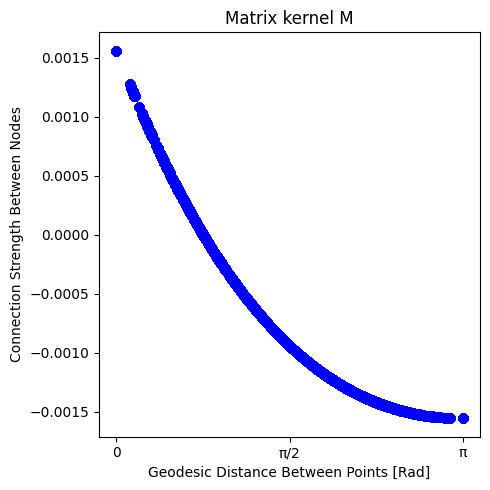

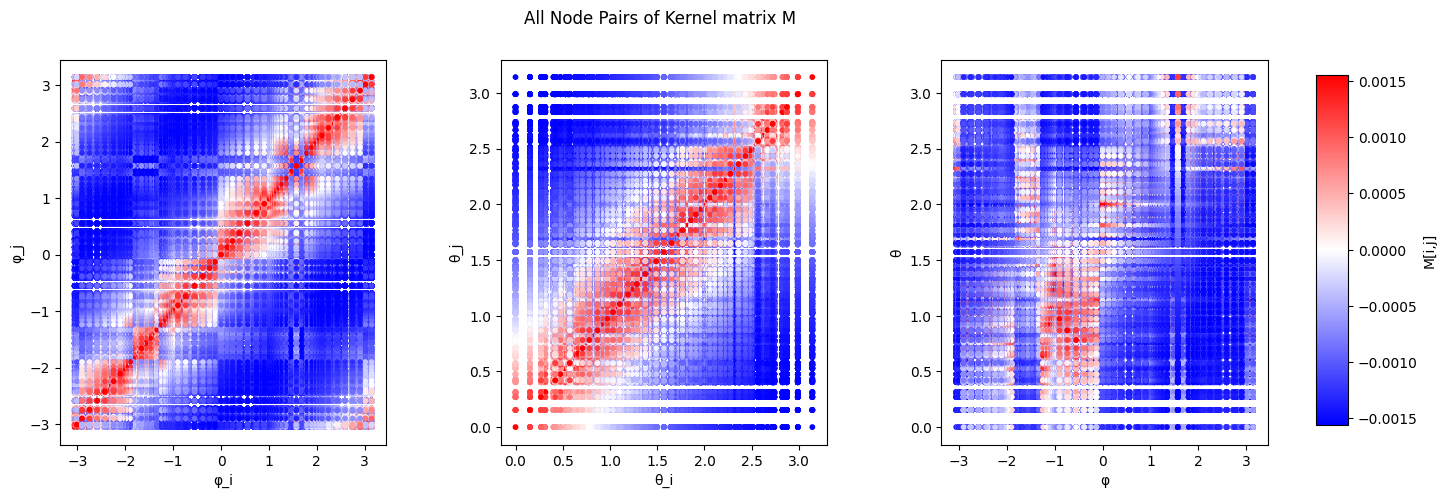

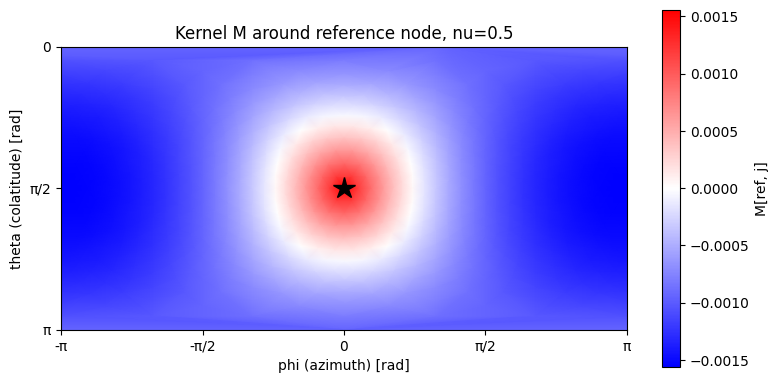

In [38]:

# Node positions and connectivity
v=0.5
alphas, M = genetate_connection_matrix(nodes, v)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(alphas, M, color='blue')
ax.set_xticks([0, np.pi/2, np.pi])
ax.set_xticklabels(['0', 'π/2', 'π'])
ax.set_title(f'Matrix kernel M')
ax.set_xlabel(f'Geodesic Distance Between Points [Rad]')
ax.set_ylabel(f'Connection Strength Between Nodes')
plt.tight_layout()
plt.show()

plot_kernel_3panel(nodes, M)
plot_kernel_one_node(0.0, 0.0, nodes, M, v)

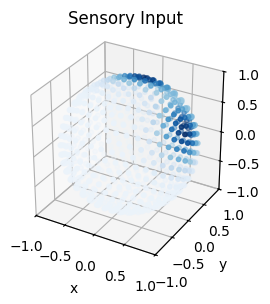

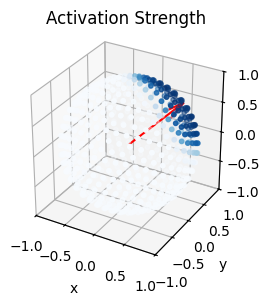

Widget(value='<iframe src="http://localhost:35093/index.html?ui=P_0x7cfed0191d20_2&reconnect=auto" class="pyvi…

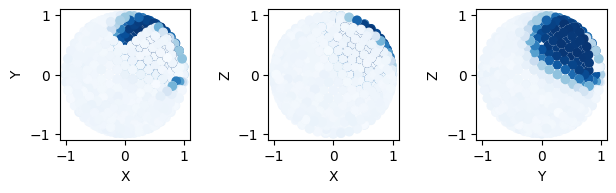

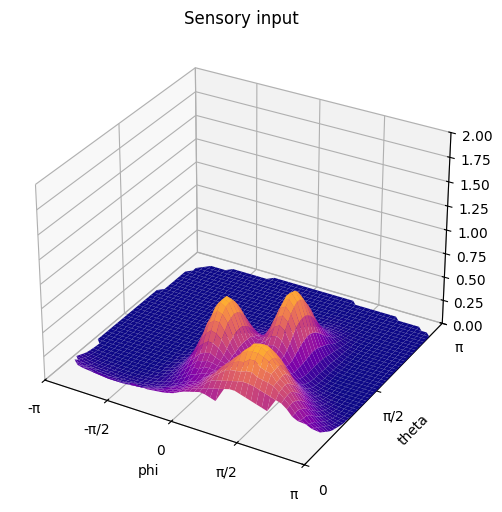

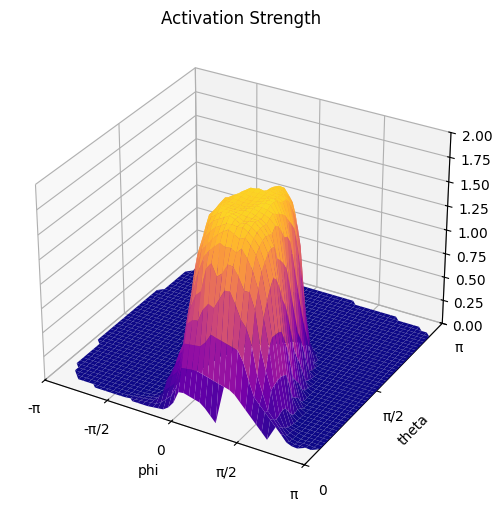

Closest node to target 0: Node 184 with phi=1.1367517107195355, theta=1.5707963267948966, with alpha: 0.031469512960908684
b_closest=0.7891602540671834
Closest node to target 1: Node 218 with phi=1.5707963267948966, theta=0.4340446160753611, with alpha: 0.03146951296090516
b_closest=0.7891602540671843
Closest node to target 2: Node 456 with phi=0.0, theta=1.1367517107195355, with alpha: 0.031469512960908684
b_closest=0.7891602540671834


In [39]:
target_cart  = symmetric_target_triplet(three_fold_axes[0], cone_angle_deg=39.0, distance=1.2857)
target_polar = cartesian_to_polar_3D(target_cart.copy())
targets = [[r, phi, theta, 20.0] for (r, phi, theta) in target_polar]

# targets = []

T = 200
u=32.0
sigma=1.0
kappa=10.0
b = generate_sensory_input(nodes, targets, kappa)
# b = generate_equal_sensory_input(nodes, targets, kappa)
y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)
z_final = y[-1]

# vel_vec_2D = find_vel_avg(theta, 
# z_final)

vis = []

for i in range(len(nodes)):
    vis.append((1, nodes[i][PHI], nodes[i][THETA]))

plot_polar_points_3D(vis, b, "Sensory Input", bool(0))
plot_polar_points_3D(vis, z_final, "Activation Strength", bool(1))

cloud = pv.PolyData(polar_to_cartesian_3D(nodes))
cloud['activation'] = z_final
plotter = pv.Plotter(window_size=[600, 300])
plotter.add_mesh(cloud, scalars='activation', cmap='plasma', point_size=10, render_points_as_spheres=True)
vel_vec = find_vel_avg_3D(nodes, z_final)
plotter.add_arrows(np.array([[0,0,0]]), np.array([vel_vec]), mag=1.0, color='red')
plotter.reset_camera() 

plotter.show()

cartesian_points = polar_to_cartesian_3D(nodes.copy())
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
ax1.scatter(cartesian_points[:, X], cartesian_points[:, Y], c=z_final, cmap='Blues')
# ax1.set_title(f'Matrix kernel M')
ax1.set_xlabel(f'X')
ax1.set_ylabel(f'Y')
ax1.set_aspect('equal')

ax2.scatter(cartesian_points[:, X], cartesian_points[:, Z], c=z_final, cmap='Blues')
# ax1.set_title(f'Matrix kernel M')
ax2.set_xlabel(f'X')
ax2.set_ylabel(f'Z')
ax2.set_aspect('equal')

ax3.scatter(cartesian_points[:, Y], cartesian_points[:, Z], c=z_final, cmap='Blues')
# ax1.set_title(f'Matrix kernel M')
ax3.set_xlabel(f'Y')
ax3.set_ylabel(f'Z')
ax3.set_aspect('equal')

plt.tight_layout()
plt.show()

#3d heatmap

plot_3d_heatmap(nodes, b, "Sensory input")
# plot_3d_heatmap(nodes, z_final, f"Activation Strength, {len(targets)} targets, u={u}, sigma={sigma}")
plot_3d_heatmap(nodes, z_final, f"Activation Strength")

# printstuff = [(vel_vec[0], vel_vec[1], vel_vec[2])] 
# print(cartesian_to_polar_3D(printstuff))

for j in range(len(targets)):
    index, value = find_closest_node(nodes, targets[j][PHI], targets[j][THETA])
    print(f'Closest node to target {j}: Node {index} with phi={nodes[index][PHI]}, theta={nodes[index][THETA]}, with alpha: {value}')
    print(f'b_closest={b[index]}')

    

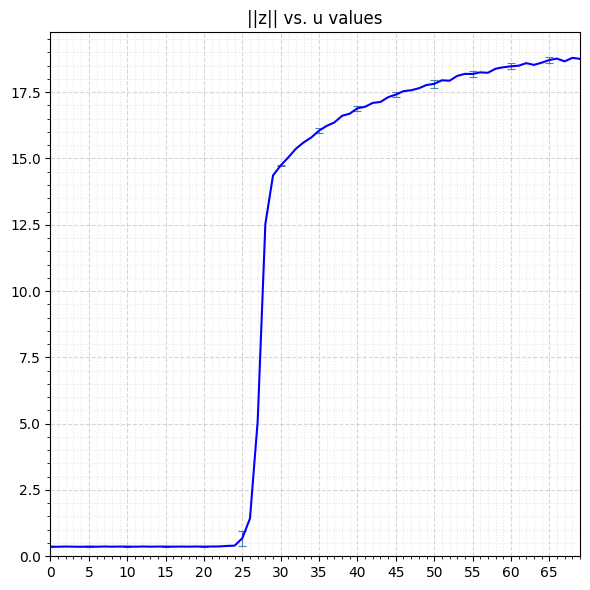

In [40]:
# Static RAN run, with multiple u's

#u_vals = [u_crit, 1.0, 3.0, 5.0, 5.85, 7.0, 10.0, 15.0, 25.0]
u_vals = []
for i in range(0,70):
    u_vals.append(float(i))

n_trials = 10
targets = []
z_vals_mean = []
z_vals_std = []

for num in range(len(u_vals)):
    T = 300
    trial_norms = []
    for trial in range(n_trials):
        b = generate_sensory_input(nodes, targets, kappa)
        y = generate_RAN_with_history(u_vals[num], N_s, M, T, dt, 0.5, beta, b)
        trial_norms.append(np.linalg.norm(y[-1]))
    z_vals_mean.append(float(np.mean(trial_norms)))
    z_vals_std.append(float(np.std(trial_norms)))

plot_scatter_regular(u_vals, z_vals_mean, 5, "||z|| vs. u values", yerr=z_vals_std, errbar_step=5)

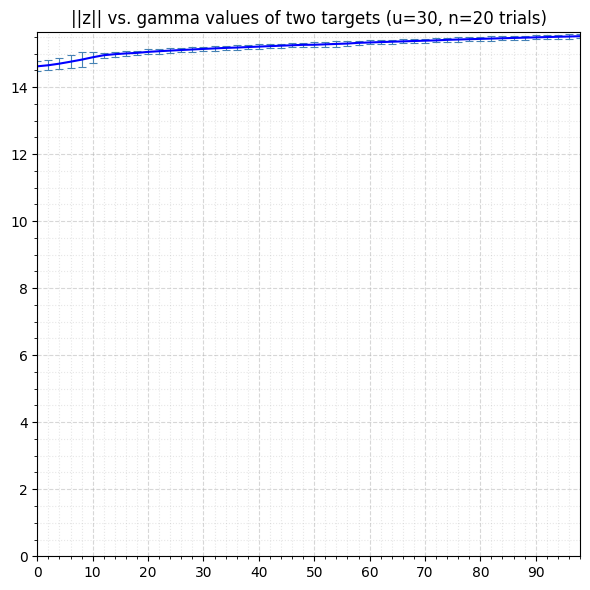

In [16]:
# Static RAN run, sweep gamma (quality) of two targets, averaged over trials

# reset targets — quality gets mutated in place below
target1 = [2.0, 0.0, np.pi/2, 20.0]
target2 = [2.0, (np.pi), np.pi/2, 20.0]
targets = [target1, target2]

gamma_vals = []
for i in range(0,100,2):
    gamma_vals.append(float(i))

n_trials = 20
T = 200
u = 30
beta = 1.5
sigma = 1.5
z_vals_mean = []
z_vals_std = []
dt = 0.1

for num in range(len(gamma_vals)):
    for j in range(len(targets)):
        targets[j][QUALITY] = gamma_vals[num]

    trial_norms = []
    for trial in range(n_trials):
        np.random.seed(trial)
        b = generate_sensory_input(nodes, targets, kappa)
        y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)
        trial_norms.append(np.linalg.norm(y[-1]))
    z_vals_mean.append(float(np.mean(trial_norms)))
    z_vals_std.append(float(np.std(trial_norms)))

plot_scatter_regular(gamma_vals, z_vals_mean, len(gamma_vals)/5,
                      f"||z|| vs. gamma values of two targets (u={u}, n={n_trials} trials)", yerr=z_vals_std, errbar_step=1,)

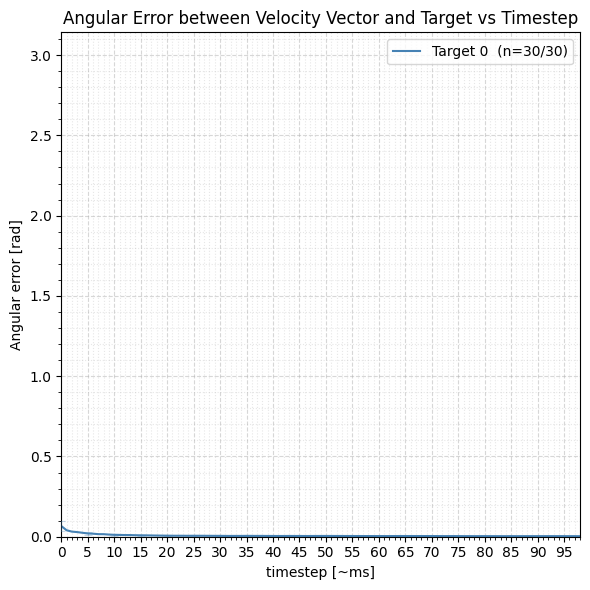

Target 0: final phase error = 0.0033 ± 0.0017 rad (n=30/30)


In [23]:
n_trials = 30
T = 100
u = 30.0

# reset targets — the gamma cell above mutates quality in-place
target1 = [2.0, 0, np.pi/2, 30.0]
target2 = [2.0, (np.pi), np.pi/2, 30.0]
targets = [target1]

b = generate_sensory_input(nodes, targets, kappa)

start_index = 0
end_index = T - 1
n_steps = end_index - start_index

# all_phase_errors[trial, target, timestep]
all_phase_errors  = np.zeros((n_trials, len(targets), n_steps))
final_selections  = np.zeros(n_trials, dtype=int)

for trial in range(n_trials):
    y = generate_RAN_with_history(u, N_s, M, T, dt, 0.5, beta, b)
    for i in range(start_index, end_index):
        vec = cartesian_to_polar_3D([find_vel_avg_3D(nodes, y[i])])[0]
        for j in range(len(targets)):
            all_phase_errors[trial, j, i - start_index] = geodesic_distance(
                [1.0, targets[j][PHI], targets[j][THETA]], vec
            )
    final_selections[trial] = int(np.argmin(all_phase_errors[trial, :, -1]))

colors      = ['steelblue', 'tomato', 'seagreen', 'darkorange']
x_vals      = np.arange(start_index, end_index)
errbar_mask = np.zeros(n_steps, dtype=bool)
errbar_mask[::5] = True

fig, ax = plt.subplots(figsize=(6, 6))

final_errors = {}

for t_idx in range(len(targets)):
    c          = colors[t_idx % len(colors)]
    trial_mask = final_selections == t_idx
    n_selected = int(np.sum(trial_mask))
    if n_selected == 0:
        continue
    errors = all_phase_errors[trial_mask, t_idx, :]
    mean   = np.mean(errors, axis=0)
    std    = np.std(errors,  axis=0)

    final_errors[t_idx] = (mean[-1], std[-1], n_selected)

    ax.plot(x_vals, mean, color=c, linewidth=1.5,
            label=f'Target {t_idx}  (n={n_selected}/{n_trials})', zorder=2)
    eb_idx = np.where(errbar_mask)[0]
    _, caps, bars = ax.errorbar(x_vals[eb_idx], mean[eb_idx], yerr=std[eb_idx],
                                color=c, ecolor=c, elinewidth=0.8, capsize=3, capthick=0.8,
                                fmt='none', zorder=3)
    for bar in bars:
        bar.set_alpha(0.3)
    for cap in caps:
        cap.set_alpha(0.3)

ax.set_xlim(x_vals[0], x_vals[-1])
ax.set_ylim(0, np.pi)
ax.xaxis.set_major_locator(ticker.MultipleLocator(int(T / 20)))
ax.grid(True, which='major', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', linestyle=':', alpha=0.3)
ax.minorticks_on()
ax.legend()
ax.set_title(f'Angular Error between Velocity Vector and Target vs Timestep')
ax.set_xlabel('timestep [~ms]')
ax.set_ylabel('Angular error [rad]')
plt.tight_layout()
plt.show()

for t_idx, (mean_final, std_final, n_selected) in final_errors.items():
    print(f'Target {t_idx}: final phase error = {mean_final:.4f} ± {std_final:.4f} rad (n={n_selected}/{n_trials})')

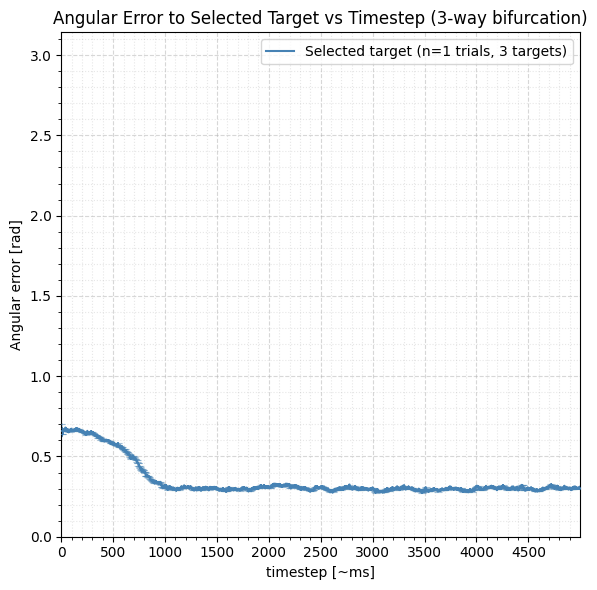

In [21]:
# 3-way bifurcation: 3 equal-quality, symmetry-matched targets, pooled over trials.
# One line = angular error to whichever target the trial actually converged to,
# so trials are pooled regardless of which of the 3 branches they picked.

n_trials = 1
T = 5000
u = 35.0        # same dynamics as the generation+plotting cell above
sigma = 1.0
kappa = 10.0    # set here so this cell does not depend on run order

# Same 3 target locations as the generation+plotting cell above: the symmetric
# triplet about the (1,1,1) 3-fold axis, 39 deg cone, distance 1.2857 -- values
# inlined as [distance, phi, theta, quality] so this cell stands on its own.
target1 = [1.2857, 1.105499, 1.567108, 20.0]
target2 = [1.2857, 1.562575, 0.465311, 20.0]
target3 = [1.2857, 0.004128, 1.105502, 20.0]
targets = [target1, target2, target3]

b = generate_sensory_input(nodes, targets, kappa)

start_index = 0
end_index = T - 1
n_steps = end_index - start_index

# all_phase_errors[trial, target, timestep]
all_phase_errors = np.zeros((n_trials, len(targets), n_steps))
final_selections = np.zeros(n_trials, dtype=int)

for trial in range(n_trials):
    y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)
    for i in range(start_index, end_index):
        vec = cartesian_to_polar_3D([find_vel_avg_3D(nodes, y[i])])[0]
        for j in range(len(targets)):
            all_phase_errors[trial, j, i - start_index] = geodesic_distance(
                [1.0, targets[j][PHI], targets[j][THETA]], vec
            )
    final_selections[trial] = int(np.argmin(all_phase_errors[trial, :, -1]))

# error to the selected target only -> one curve for every trial
selected_errors = all_phase_errors[np.arange(n_trials), final_selections, :]
mean = np.mean(selected_errors, axis=0)
std  = np.std(selected_errors,  axis=0)

x_vals      = np.arange(start_index, end_index)
errbar_mask = np.zeros(n_steps, dtype=bool)
errbar_mask[::5] = True
eb_idx      = np.where(errbar_mask)[0]

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(x_vals, mean, color='steelblue', linewidth=1.5,
        label=f'Selected target (n={n_trials} trials, 3 targets)', zorder=2)
_, caps, bars = ax.errorbar(x_vals[eb_idx], mean[eb_idx], yerr=std[eb_idx],
                            color='steelblue', ecolor='steelblue', elinewidth=0.8,
                            capsize=3, capthick=0.8, fmt='none', zorder=3)
for bar in bars:
    bar.set_alpha(0.3)
for cap in caps:
    cap.set_alpha(0.3)

ax.set_xlim(x_vals[0], x_vals[-1])
ax.set_ylim(0, np.pi)
ax.xaxis.set_major_locator(ticker.MultipleLocator(int(T / 10)))
ax.grid(True, which='major', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', linestyle=':', alpha=0.3)
ax.minorticks_on()
ax.legend()
ax.set_title('Angular Error to Selected Target vs Timestep (3-way bifurcation)')
ax.set_xlabel('timestep [~ms]')
ax.set_ylabel('Angular error [rad]')
plt.tight_layout()
plt.show()

# print(f'final phase error = {mean[-1]:.4f} +/- {std[-1]:.4f} rad (n={n_trials})')
# print('branch split across the 3 targets: '
#       f'{np.bincount(final_selections, minlength=len(targets)).tolist()}')
# print('\ntimestep   mean [rad]   std [rad]')
# for i in eb_idx:
#     print(f'{x_vals[i]:8d}   {mean[i]:10.4f}   {std[i]:9.4f}')


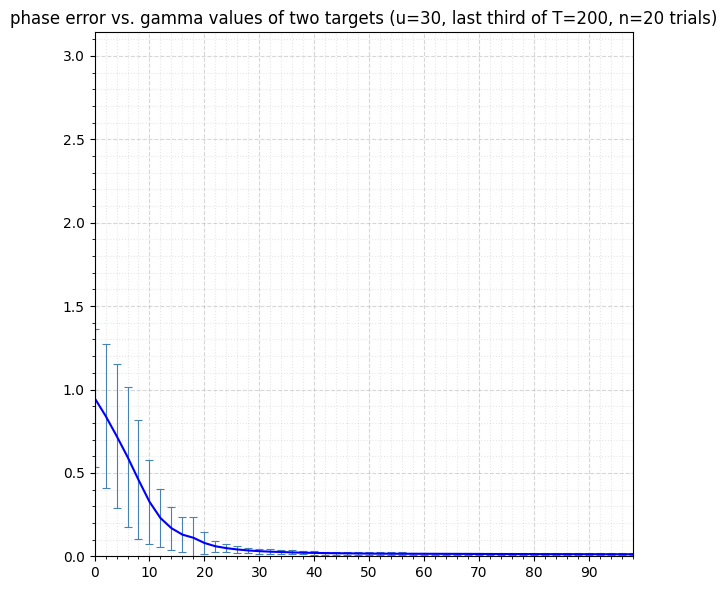

In [13]:
# Static RAN run, sweep gamma (quality) of two targets — phase error averaged over the last third of the run

target1 = [2.0, 0, np.pi/2, 20.0]
target2 = [2.0, (np.pi), np.pi/2, 20.0]
targets = [target1, target2]

gamma_vals = []
for i in range(0, 100, 2):
    gamma_vals.append(float(i))

n_trials = 10
T = 200
u = 30.0
beta = 1.5
sigma = 1.5
dt = 0.1

start_index = 2 * T // 3   # last third of the run

phase_err_mean = []
phase_err_std = []

for num in range(len(gamma_vals)):
    for j in range(len(targets)):
        targets[j][QUALITY] = gamma_vals[num]

    b = generate_sensory_input(nodes, targets, kappa)

    trial_errors = []
    for trial in range(n_trials):
        np.random.seed(trial)
        y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)

        target_errors = np.zeros((len(targets), T - start_index))
        for i in range(start_index, T):
            vec = cartesian_to_polar_3D([find_vel_avg_3D(nodes, y[i])])[0]
            for j in range(len(targets)):
                target_errors[j, i - start_index] = geodesic_distance(
                    [1.0, targets[j][PHI], targets[j][THETA]], vec
                )

        # whichever target this trial settled on — the one with the smaller mean error over the window
        trial_errors.append(np.min(np.mean(target_errors, axis=1)))

    phase_err_mean.append(float(np.mean(trial_errors)))
    phase_err_std.append(float(np.std(trial_errors)))

plot_scatter_regular(gamma_vals, phase_err_mean, len(gamma_vals)/5,
                      f"phase error vs. gamma values of two targets (u={u}, last third of T={T}, n={n_trials} trials)",
                      ymax=np.pi, yerr=phase_err_std, errbar_step=1)

In [18]:
import time 

num_trials = 100
times = np.zeros(num_trials)

T = 400
u=6.0
sigma=1.5

# discard first run 
b = generate_sensory_input(nodes, targets, kappa)
y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)

for i in range(len(times)):
    t0 = time.perf_counter()
    y = generate_RAN_with_history(u, N_s, M, T, dt, sigma, beta, b)
    t_next = time.perf_counter()
    times[i] = t_next - t0

print(f"mean RAN generation time: {np.mean(times)}")
print(f"std deviation: {np.std(times)}")
print(f"std error: {np.round((np.std(times)/np.sqrt(num_trials) * 100),2)}%")
print(f"Fastest runtime: {np.min(times)}")
print(f"Update rate per tick: {np.round(num_trials/(np.mean(times)),2)} hz")





mean RAN generation time: 0.4567958366099947
std deviation: 0.10913503887147019
std error: 1.09%
Fastest runtime: 0.2664601120000043
Update rate per tick: 218.92 hz


- plot of matrix for pole vs other nodes, and equator vs other nodes
- 3 target tracking: line, triangle, -     - 
                                        -

- torus shape? find reasoning for spherical attractor (matches geometry of the problem, no gimbal lock because using x y z to read off two angles, extra number eliminates gimbal lock problem - collapses theta and phi to pos = 0 0 1)
- analytical methods jacobian eigenvector linearization etc
- hardware